In [1]:

!pip install medmnist torch torchvision matplotlib scikit-learn



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


Training: Normal = 1214, Pneumonia = 3494
Validation: Normal = 135, Pneumonia = 389
Testing: Normal = 234, Pneumonia = 390


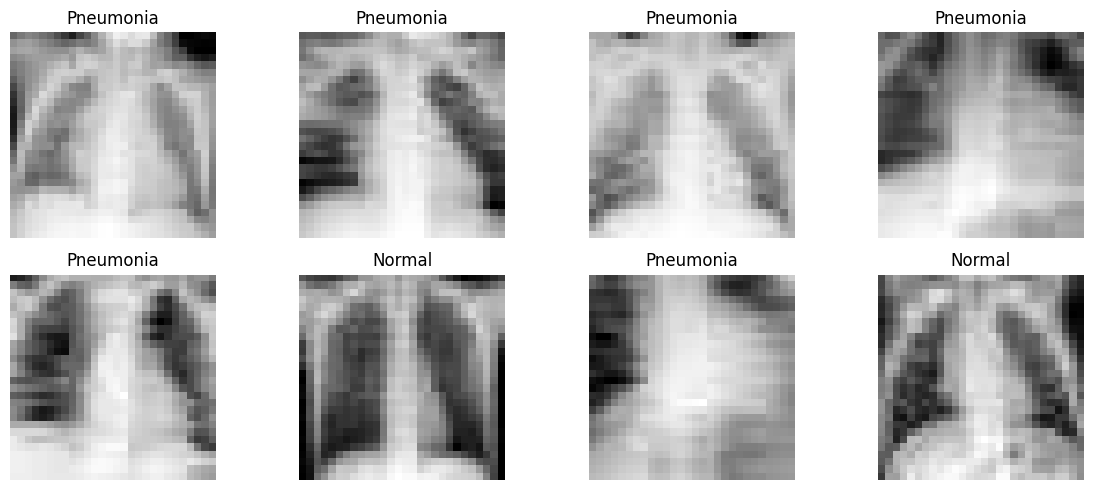

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Check how many images belong to each class
for name, dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Testing", test_dataset)
]:
    labels = np.array(dataset.labels).reshape(-1)
    normal = np.sum(labels == 0)
    pneumonia = np.sum(labels == 1)

    print(f"{name}: Normal = {normal}, Pneumonia = {pneumonia}")

# Display 8 sample X-rays from the training dataset
plt.figure(figsize=(12, 5))

for i in range(8):
    image = train_dataset.imgs[i]
    label = int(train_dataset.labels[i].item())

    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title("Pneumonia" if label == 1 else "Normal")
    plt.axis("off")

plt.tight_layout()
plt.show()

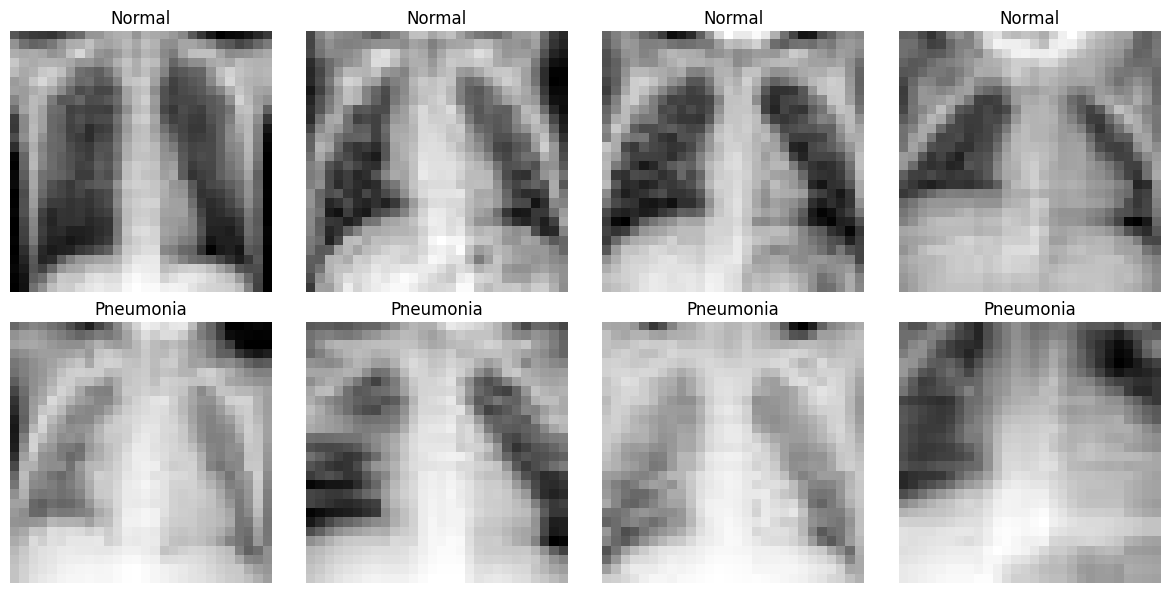

In [7]:
import matplotlib.pyplot as plt
import numpy as np

images = train_dataset.imgs
labels = train_dataset.labels.reshape(-1)

normal_indices = np.where(labels == 0)[0][:4]
pneumonia_indices = np.where(labels == 1)[0][:4]

selected_indices = list(normal_indices) + list(pneumonia_indices)

plt.figure(figsize=(12, 6))

for i, idx in enumerate(selected_indices):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[idx], cmap="gray")
    label = "Normal" if labels[idx] == 0 else "Pneumonia"
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()


In [8]:
import torch
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# Convert images to PyTorch tensors
def prepare_data(dataset):
    images = dataset.imgs.astype(np.float32) / 255.0
    labels = dataset.labels.reshape(-1).astype(np.int64)

    images = torch.tensor(images).unsqueeze(1)
    labels = torch.tensor(labels)

    return TensorDataset(images, labels)

train_data = prepare_data(train_dataset)
val_data = prepare_data(val_dataset)
test_data = prepare_data(test_dataset)

# Load data in batches
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Image shape:", train_data[0][0].shape)

Training batches: 148
Validation batches: 17
Testing batches: 20
Image shape: torch.Size([1, 28, 28])


In [4]:
from medmnist import PneumoniaMNIST, INFO

train_dataset = PneumoniaMNIST(split="train", download=True, size=28)
val_dataset = PneumoniaMNIST(split="val", download=True, size=28)
test_dataset = PneumoniaMNIST(split="test", download=True, size=28)

print("Train:", train_dataset.imgs.shape)
print("Validation:", val_dataset.imgs.shape)
print("Test:", test_dataset.imgs.shape)

print("Labels:", INFO["pneumoniamnist"]["label"])

Train: (4708, 28, 28)
Validation: (524, 28, 28)
Test: (624, 28, 28)
Labels: {'0': 'normal', '1': 'pneumonia'}


In [9]:
import torch.nn as nn
import torch.optim as optim

class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = PneumoniaCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Device:", device)
print("CNN created successfully!")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cpu
CNN created successfully!
Trainable parameters: 105346


In [10]:
from sklearn.metrics import accuracy_score

epochs = 10

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_loss/len(train_loader):.4f} | "
        f"Validation Accuracy: {val_accuracy*100:.2f}%"
    )


Epoch 1/10 | Loss: 0.4305 | Validation Accuracy: 87.40%
Epoch 2/10 | Loss: 0.2267 | Validation Accuracy: 95.61%
Epoch 3/10 | Loss: 0.1806 | Validation Accuracy: 95.80%
Epoch 4/10 | Loss: 0.1630 | Validation Accuracy: 96.18%
Epoch 5/10 | Loss: 0.1374 | Validation Accuracy: 96.18%
Epoch 6/10 | Loss: 0.1291 | Validation Accuracy: 96.18%
Epoch 7/10 | Loss: 0.1218 | Validation Accuracy: 96.37%
Epoch 8/10 | Loss: 0.1201 | Validation Accuracy: 96.37%
Epoch 9/10 | Loss: 0.1034 | Validation Accuracy: 96.56%
Epoch 10/10 | Loss: 0.0964 | Validation Accuracy: 96.76%


In [11]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

model.eval()

all_predictions = []
all_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

tn, fp, fn, tp = cm.ravel()

print("CONFUSION MATRIX")
print(cm)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Normal", "Pneumonia"],
    digits=4
))

print("False Negatives:", fn)
print("False Positives:", fp)
print("True Negatives:", tn)
print("True Positives:", tp)


CONFUSION MATRIX
[[137  97]
 [  2 388]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9856    0.5855    0.7346       234
   Pneumonia     0.8000    0.9949    0.8869       390

    accuracy                         0.8413       624
   macro avg     0.8928    0.7902    0.8107       624
weighted avg     0.8696    0.8413    0.8298       624

False Negatives: 2
False Positives: 97
True Negatives: 137
True Positives: 388


In [12]:
from sklearn.metrics import confusion_matrix, balanced_accuracy_score
import numpy as np

model.eval()

val_probs = []
val_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        val_probs.extend(probabilities[:, 1].cpu().numpy())
        val_labels.extend(labels.numpy())

val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

print("VALIDATION THRESHOLD ANALYSIS")

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    predictions = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_labels, predictions, labels=[0, 1]
    ).ravel()

    normal_recall = tn / (tn + fp)
    pneumonia_recall = tp / (tp + fn)
    balanced_acc = (normal_recall + pneumonia_recall) / 2

    print(
        f"Threshold: {threshold:.1f} | "
        f"Normal recall: {normal_recall:.3f} | "
        f"Pneumonia recall: {pneumonia_recall:.3f} | "
        f"Balanced accuracy: {balanced_acc:.3f} | "
        f"FP: {fp} | FN: {fn}"
    )

VALIDATION THRESHOLD ANALYSIS
Threshold: 0.3 | Normal recall: 0.844 | Pneumonia recall: 0.992 | Balanced accuracy: 0.918 | FP: 21 | FN: 3
Threshold: 0.4 | Normal recall: 0.896 | Pneumonia recall: 0.982 | Balanced accuracy: 0.939 | FP: 14 | FN: 7
Threshold: 0.5 | Normal recall: 0.926 | Pneumonia recall: 0.982 | Balanced accuracy: 0.954 | FP: 10 | FN: 7
Threshold: 0.6 | Normal recall: 0.926 | Pneumonia recall: 0.972 | Balanced accuracy: 0.949 | FP: 10 | FN: 11
Threshold: 0.7 | Normal recall: 0.948 | Pneumonia recall: 0.967 | Balanced accuracy: 0.957 | FP: 7 | FN: 13
Threshold: 0.8 | Normal recall: 0.956 | Pneumonia recall: 0.959 | Balanced accuracy: 0.957 | FP: 6 | FN: 16
Threshold: 0.9 | Normal recall: 0.978 | Pneumonia recall: 0.938 | Balanced accuracy: 0.958 | FP: 3 | FN: 24


In [13]:
import numpy as np

# Model confidence = highest probability assigned to either class
val_confidence = np.maximum(val_probs, 1 - val_probs)

# Model's predicted class
val_predictions = (val_probs >= 0.5).astype(int)

print("SECONDLOOK - VALIDATION SELECTIVE PREDICTION")
print("-" * 65)

for threshold in [0.60, 0.70, 0.80, 0.90, 0.95]:
    accepted = val_confidence >= threshold

    accepted_predictions = val_predictions[accepted]
    accepted_labels = val_labels[accepted]

    coverage = accepted.mean()

    if accepted.sum() == 0:
        continue

    errors = accepted_predictions != accepted_labels
    selective_accuracy = 1 - errors.mean()

    tn, fp, fn, tp = confusion_matrix(
        accepted_labels,
        accepted_predictions,
        labels=[0, 1]
    ).ravel()

    print(f"\nConfidence threshold: {threshold:.2f}")
    print(f"Coverage: {coverage*100:.2f}%")
    print(f"Accepted: {accepted.sum()}")
    print(f"Sent for review: {(~accepted).sum()}")
    print(f"Accuracy on accepted: {selective_accuracy*100:.2f}%")
    print(f"False positives: {fp}")
    print(f"False negatives: {fn}")

SECONDLOOK - VALIDATION SELECTIVE PREDICTION
-----------------------------------------------------------------

Confidence threshold: 0.60
Coverage: 98.47%
Accepted: 516
Sent for review: 8
Accuracy on accepted: 96.71%
False positives: 10
False negatives: 7

Confidence threshold: 0.70
Coverage: 95.42%
Accepted: 500
Sent for review: 24
Accuracy on accepted: 98.00%
False positives: 7
False negatives: 3

Confidence threshold: 0.80
Coverage: 93.89%
Accepted: 492
Sent for review: 32
Accuracy on accepted: 98.37%
False positives: 6
False negatives: 2

Confidence threshold: 0.90
Coverage: 87.02%
Accepted: 456
Sent for review: 68
Accuracy on accepted: 98.90%
False positives: 3
False negatives: 2

Confidence threshold: 0.95
Coverage: 77.10%
Accepted: 404
Sent for review: 120
Accuracy on accepted: 99.75%
False positives: 1
False negatives: 0


In [15]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

# Test predictions and probabilities collected earlier
test_probs = np.array(all_probabilities)
test_labels = np.array(all_labels)

test_predictions = (test_probs >= 0.5).astype(int)
test_confidence = np.maximum(test_probs, 1 - test_probs)

# Original model: accepts every prediction
print("BASELINE MODEL")
print("Accuracy:", round(
    accuracy_score(test_labels, test_predictions) * 100, 2
), "%")

# SECONDLOOK: accepts only sufficiently confident predictions
threshold = 0.90
accepted = test_confidence >= threshold

accepted_predictions = test_predictions[accepted]
accepted_labels = test_labels[accepted]

tn, fp, fn, tp = confusion_matrix(
    accepted_labels,
    accepted_predictions,
    labels=[0, 1]
).ravel()

print("\nSECONDLOOK")
print("Confidence threshold:", threshold)
print("Coverage:", round(accepted.mean() * 100, 2), "%")
print("Accepted:", accepted.sum())
print("Sent for human review:", (~accepted).sum())

print("Accepted prediction accuracy:", round(
    accuracy_score(accepted_labels, accepted_predictions) * 100, 2
), "%")

print("False positives:", fp)
print("False negatives:", fn)

print("\nActual classes sent for review:")
print("Normal:", (test_labels[~accepted] == 0).sum())
print("Pneumonia:", (test_labels[~accepted] == 1).sum())

BASELINE MODEL
Accuracy: 84.13 %

SECONDLOOK
Confidence threshold: 0.9
Coverage: 78.69 %
Accepted: 491
Sent for human review: 133
Accepted prediction accuracy: 90.02 %
False positives: 49
False negatives: 0

Actual classes sent for review:
Normal: 118
Pneumonia: 15


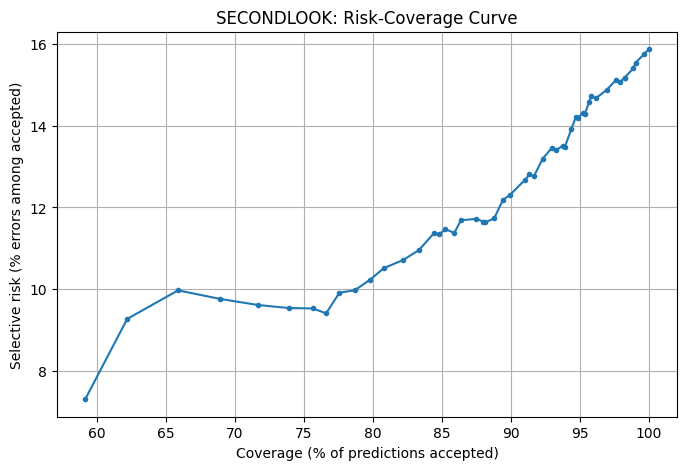

In [16]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = np.linspace(0.50, 0.99, 50)

coverages = []
risks = []

for threshold in thresholds:
    accepted = test_confidence >= threshold

    coverage = accepted.mean()

    if accepted.sum() == 0:
        continue

    errors = (
        test_predictions[accepted] != test_labels[accepted]
    )

    risk = errors.mean()

    coverages.append(coverage)
    risks.append(risk)

plt.figure(figsize=(8, 5))
plt.plot(
    np.array(coverages) * 100,
    np.array(risks) * 100,
    marker="."
)

plt.xlabel("Coverage (% of predictions accepted)")
plt.ylabel("Selective risk (% errors among accepted)")
plt.title("SECONDLOOK: Risk-Coverage Curve")
plt.grid(True)
plt.show()

In [19]:
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "model_architecture": "PneumoniaCNN",
    "confidence_threshold": 0.90,
    "image_size": 28,
    "class_mapping": {
        0: "Normal",
        1: "Pneumonia"
    }
}, "secondlook_model.pth")

print("SECONDLOOK model saved successfully!")

SECONDLOOK model saved successfully!


In [21]:
from google.colab import files

files.download("secondlook_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>